## Integrate network travelling with OpenCLSim activities

In this notebook, we combine `OpenCLSim` activity cycles with `OpenTNSim` travelling on network. The usecase for this container is unloading a container vessel, and moving containers into different container yards using terminal vehicles to move containers to the destination yard.

_Description of the casus_
The casus silumated here is a simple representation of a container yard. A container vessel is to be unloaded by a quay crane, road vehicles are used to transport the containers from the quay to the container yard, where a yard crane picks up containers from the vehicles to store them in the yard.

All durations, locations, speed, etc are fictional, only to illustrate the concept.

#### 0. Import libraries

In [1]:
# generic libraries
import simpy
import pandas as pd
import networkx as nx
from openclsim.plot import get_log_dataframe
from shapely.geometry import Point

# openclsim libraries
import openclsim.core as clcore
import openclsim.model as clmodel

# opentnsim libraries
import opentnsim
import opentnsim.core as tncore
import opentnsim.model as tnmodel


print("This notebook is executed with OpenTNSim version {}".format(opentnsim.__version__))

This notebook is executed with OpenTNSim version 1.3.7


#### 1. Define object classes

Three concepts are needed in this simulation:

- `Site` representing a fixed location in the simulation, e.g. the quay, container yards and waypoints on the road network. Sites can potentially store shipping containers.
- `Mover` which is a resource that can transport a shipping container between sites.
- `CargoHandler` which takes care of moving shipping containers from e.g. a site to a mover.

In [2]:
# generic site class
Site = type(
    "Site",
    (
        clcore.Identifiable,
        clcore.Log,
        clcore.Locatable,
        clcore.HasResource,
        clcore.HasContainer,
    ),
    {},
)

# generic mover class
Mover = type(
    "Mover",
    (
        clcore.Identifiable,
        clcore.HasResource,
        clcore.HasContainer,
        tncore.Movable,
    ),
    {},
)

# the cargo handler
CargoHandler = type(
    "CargoHandler",
    (
        clcore.Identifiable,
        clcore.Log,
        clcore.Locatable,
        clcore.HasResource,
        clcore.Processor,
    ),
    {},
)

#### 2. Create graph

In this example the graph represents the road network that transport vehicles can use to transport shipping containers from the quay to different yards. The conceptual network looks as follows:

```
(WP3) -->-- (Y2) -->-- (WP4)
  |                      |  
(WP2) -->-- (Y1) -->-- (WP5)
  |                      |  
(WP1) --<-- (Q)  --<-- (WP6)
```

Where `(Q)` represents the quay, and `(Y1)` and `(Y2)` the two container yards. The other nodes
are simply waypoints defining the network.

The graph is single way traffic. That is, in order to drop off a container at yard 1, a vehicle moves from `(Q)` to `(Y1)` through `(WP1)` and `(WP2)`, unload the container and return to the quad through `(WP5)` and `(WP6)`.

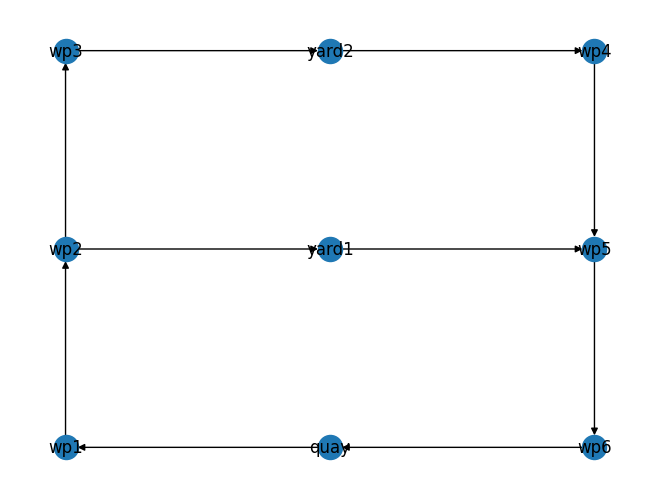

In [3]:
# define the graph nodes (location coordinates are fictional)
nodes = [
    ('quay', Point(1, 0)),
    ('yard1', Point(1, 1)),
    ('yard2', Point(1, 2)),
    ('wp1', Point(0, 0)),
    ('wp2', Point(0, 1)),
    ('wp3', Point(0, 2)),
    ('wp4', Point(2, 2)),
    ('wp5', Point(2, 1)),
    ('wp6', Point(2, 0)),
]

# define the connecting edges
edges = [
    ('quay', 'wp1'),
    ('wp1', 'wp2'),
    ('wp2', 'wp3'),
    ('wp2', 'yard1'),
    ('wp3', 'yard2'),
    ('yard1', 'wp5'),
    ('yard2', 'wp4'),
    ('wp4', 'wp5'),
    ('wp5', 'wp6'),
    ('wp6', 'quay'),
]

# create the directed graph
G = nx.DiGraph()
for node_name, node_geometry in nodes:
    G.add_node(
        node_name,
        pos=(node_geometry.x, node_geometry.y),
        geometry=node_geometry, # geometry attribute needed to OpenTNSim movable
    )
G.add_edges_from(edges)

# visualize
nx.draw(G, with_labels=True, pos=nx.get_node_attributes(G, 'pos'))

#### 3. Run simulation

In [4]:
# settings
N_VEHICLES = 5
LOADING_TIME_S = 30
UNLOADING_TIME_S = 20

In [5]:
# initialize the environment
env = simpy.Environment()
env.graph = G
registry = {}

In [6]:
# define sites
vessel = Site(
    env=env,
    name='vessel',
    geometry=G.nodes['quay']['geometry'],
    capacity=500, # max capacity, i.e. nr of shipping containers
    level=500, # capacity at start of simulation
)

yard1 = Site(
    env=env,
    name='yard1',
    geometry=G.nodes['yard1']['geometry'],
    capacity=9999, # dummy value, make sure it is large enough to empty the vessel
    level=0, # yard is empty initially
)

yard2 = Site(
    env=env,
    name='yard2',
    geometry=G.nodes['yard2']['geometry'],
    capacity=9999,
    level=0,
)

In [7]:
# cargo handlers
quay_crane = CargoHandler(
    env=env,
    name='quay_crane',
    geometry=G.nodes['quay']['geometry'],
    nr_resources=1, # can be claimed by one activity at a time
)

yard1_crane = CargoHandler(
    env=env,
    name='yard1_crane',
    geometry=G.nodes['yard1']['geometry'],
    nr_resources=1,
)

yard2_crane = CargoHandler(
    env=env,
    name='yard2_crane',
    geometry=G.nodes['yard2']['geometry'],
    nr_resources=1,
)

In [8]:
# vehicles
vehicles = []
for vehicle_nr in range(N_VEHICLES):
    vehicles.append(
        Mover(
            env=env,
            name=f'vehicle{vehicle_nr+1}',
            geometry=G.nodes['quay']['geometry'], # spawn at the quay initially
            capacity=1, # can store one shipping container at a time
            v=10, # dummy speed
            route=[], # no route assigned initially
        )
    )

In [9]:
# simulation activities
vehicle_activities = []
for i, vehicle in enumerate(vehicles):
    # predefine the route and objects to use
    if i % 2 == 0:
        route_to = ['quay', 'wp1', 'wp2', 'wp3', 'yard2']
        route_back = ['yard2', 'wp4', 'wp5', 'wp6', 'quay']
        yard = yard2
        yard_crane = yard2_crane
    else:
        route_to = ['quay', 'wp1', 'wp2', 'yard1']
        route_back = ['yard1', 'wp5', 'wp6', 'quay']
        yard = yard1
        yard_crane = yard1_crane

    # single run activity: load, move to yard, unload, move back
    single_run = [
        clmodel.ShiftAmountActivity(
            env=env,
            registry=registry,
            name=f'{vehicle.name}_loading',
            processor=quay_crane,
            origin=vessel,
            destination=vehicle,
            amount=1,
            duration=LOADING_TIME_S,
        ),
        tnmodel.NetworkMoveActivity(
            env=env,
            registry=registry,
            name=f"{vehicle.name}_move_to_yard",
            mover=vehicle,
            route=route_to,
        ),
        clmodel.ShiftAmountActivity(
            env=env,
            registry=registry,
            name=f'{vehicle.name}_unloading',
            processor=yard_crane,
            origin=vehicle,
            destination=yard,
            amount=1,
            duration=UNLOADING_TIME_S,
        ),
        tnmodel.NetworkMoveActivity(
            env=env,
            registry=registry,
            name=f"{vehicle.name}_move_to_quay",
            mover=vehicle,
            route=route_back,
        ),
    ]

    # repeat while vessel not empty
    vehicle_activities.append(
        clmodel.WhileActivity(
            env=env,
            name=f"{vehicle.name}_while",
            registry=registry,
            sub_processes=single_run,
            condition_event=[{"type": "container", "concept": vessel, "state": "empty"}],
        )
    )

# main activity: run all individual vehicle activities in parallel
main_activity = clmodel.ParallelActivity(
    env=env,
    name="main_transport_activity",
    registry=registry,
    sub_processes=vehicle_activities,
)

# register
clmodel.register_processes([main_activity])

In [10]:
# finally, run the simulation
env.run()

#### 4. Inspect output

The logbooks of the vehicles indicate that they indeed perform their transport cycles, and travel
across the road network.


In [25]:
df_log = get_log_dataframe(vehicles[0])
display(df_log.head(12))

,Activity,Timestamp,ActivityState,geometry,container level,message,distance
0,a1a02562-3e5a-4807-87eb-94fe299d60b8,1970-01-01 00:00:00.000000,START,POINT (1 0),0.0,NaN,NaN
1,a1a02562-3e5a-4807-87eb-94fe299d60b8,1970-01-01 00:00:30.000000,STOP,POINT (1 0),1.0,NaN,NaN
2,d4be52e6-6c63-4bc5-9853-d08aec62dc1b,1970-01-01 00:00:30.000000,START,POINT (1 0),1.0,Sailing from node quay to node wp1,0.000000
3,d4be52e6-6c63-4bc5-9853-d08aec62dc1b,1970-01-01 03:06:01.949079,STOP,POINT (1 0),1.0,Sailing from node quay to node wp1,111319.490793
4,d4be52e6-6c63-4bc5-9853-d08aec62dc1b,1970-01-01 03:06:01.949079,START,POINT (0 0),1.0,Sailing from node wp1 to node wp2,111319.490793
5,d4be52e6-6c63-4bc5-9853-d08aec62dc1b,1970-01-01 06:11:33.898159,STOP,POINT (0 0),1.0,Sailing from node wp1 to node wp2,222638.981587
6,d4be52e6-6c63-4bc5-9853-d08aec62dc1b,1970-01-01 06:11:33.898159,START,POINT (0 1),1.0,Sailing from node wp2 to node wp3,222638.981587
7,d4be52e6-6c63-4bc5-9853-d08aec62dc1b,1970-01-01 09:17:05.847238,STOP,POINT (0 1),1.0,Sailing from node wp2 to node wp3,333958.472380
8,d4be52e6-6c63-4bc5-9853-d08aec62dc1b,1970-01-01 09:17:05.847238,START,POINT (0 2),1.0,Sailing from node wp3 to node yard2,333958.472380
9,d4be52e6-6c63-4bc5-9853-d08aec62dc1b,1970-01-01 12:22:37.796317,STOP,POINT (0 2),1.0,Sailing from node wp3 to node yard2,445277.963173
